import csv and check the head of the dataframe 

In [64]:
import matplotlib.pyplot as plt 
import pandas as pd 

df = pd.read_csv("/Users/hayansaab/Desktop/research/Sparkov_Data_Generation/output_data/transactions.csv", sep= '|')
print(df.head())



           ssn            cc_num    first   last gender  \
0  082-30-1655  5332871012269166  Matthew  Mejia      M   
1  082-30-1655  5332871012269166  Matthew  Mejia      M   
2  082-30-1655  5332871012269166  Matthew  Mejia      M   
3  082-30-1655  5332871012269166  Matthew  Mejia      M   
4  082-30-1655  5332871012269166  Matthew  Mejia      M   

                      street          city state    zip      lat     long  \
0  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
1  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
2  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
3  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
4  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   

   city_pop        job         dob      acct_num                      profile  \
0    179275  Professor  1971-08-05  269419548116  adults_50up_male_urban.json   
1    179275  Profess

In [65]:
print(df.shape)

(75699, 32)


In [66]:
pd.set_option('display.max_columns', None)
print(df.head())

           ssn            cc_num    first   last gender  \
0  082-30-1655  5332871012269166  Matthew  Mejia      M   
1  082-30-1655  5332871012269166  Matthew  Mejia      M   
2  082-30-1655  5332871012269166  Matthew  Mejia      M   
3  082-30-1655  5332871012269166  Matthew  Mejia      M   
4  082-30-1655  5332871012269166  Matthew  Mejia      M   

                      street          city state    zip      lat     long  \
0  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
1  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
2  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
3  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
4  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   

   city_pop        job         dob      acct_num                      profile  \
0    179275  Professor  1971-08-05  269419548116  adults_50up_male_urban.json   
1    179275  Profess

In [67]:
print(df['trans_date'].dtype)


object


In [68]:
df['trans_date'] = pd.to_datetime(df['trans_date'])

           ssn            cc_num    first   last gender  \
0  082-30-1655  5332871012269166  Matthew  Mejia      M   
1  082-30-1655  5332871012269166  Matthew  Mejia      M   
2  082-30-1655  5332871012269166  Matthew  Mejia      M   
3  082-30-1655  5332871012269166  Matthew  Mejia      M   
4  082-30-1655  5332871012269166  Matthew  Mejia      M   

                      street          city state    zip      lat     long  \
0  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
1  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
2  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
3  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   
4  7525 Clark Grove Apt. 928  Newport News    VA  23603  37.1989 -76.5821   

   city_pop        job         dob      acct_num income_band      education  \
0    179275  Professor  1971-08-05  269419548116       100k+  bachelor_plus   
1    179275  Professor  

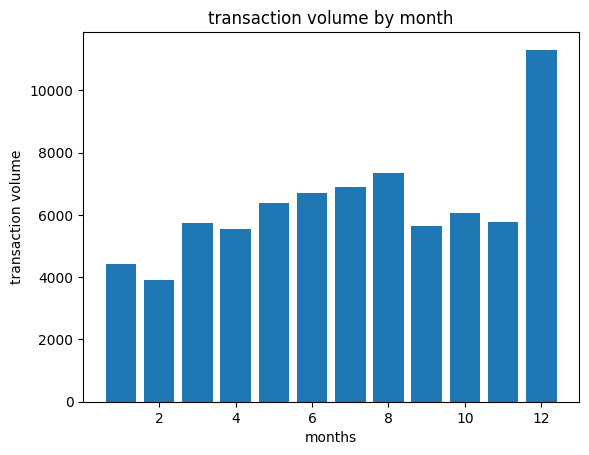

In [69]:
new = df.drop(columns = ['profile', 'trans_num',])
print(new.head())
months = new['trans_date'].dt.month
months_matrix = months.value_counts().sort_index()

plt.bar(months_matrix.index, months_matrix.values)
plt.xlabel('months')
plt.ylabel('transaction volume')
plt.title("transaction volume by month")
plt.show()

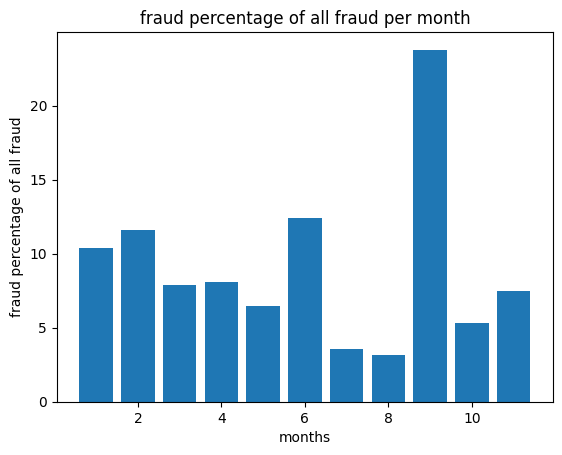

In [70]:
total_fraud = (new['is_fraud']==1).sum()
fraud_df = new.loc[new['is_fraud'] == 1, 'trans_date']
fraud_counts = fraud_df.dt.month.value_counts().sort_index()
plt.bar(fraud_counts.index, fraud_counts.values/total_fraud * 100)

plt.xlabel('months')
plt.ylabel('fraud percentage of all fraud')
plt.title('fraud percentage of all fraud per month')
plt.show()

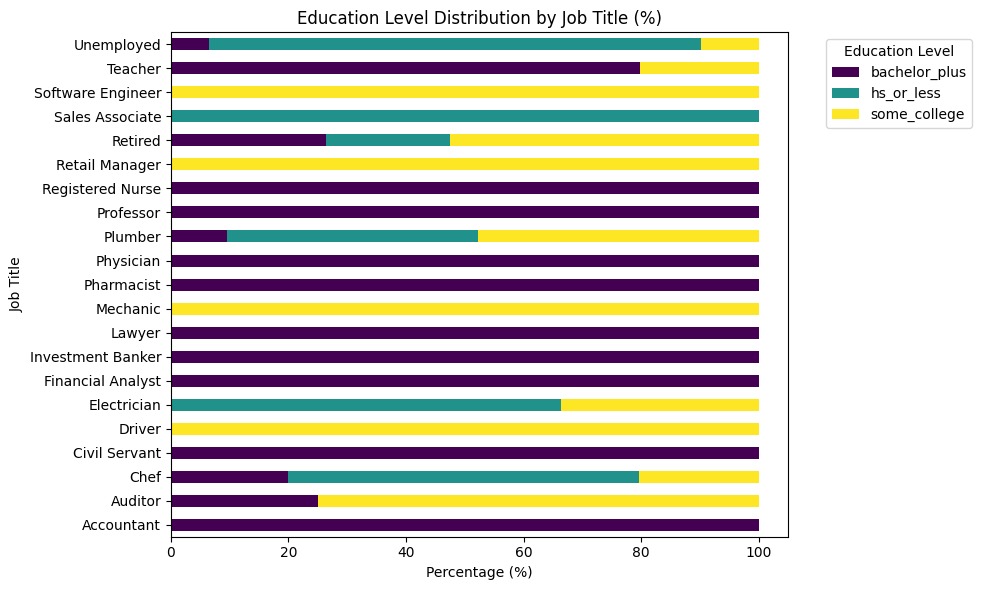

In [71]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Create cross-tabulation (normalized to percentages per job)
job_edu = pd.crosstab(new['job'], new['education'], normalize='index') * 100

# 2. Plot 100% Stacked Bar Chart
job_edu.plot(kind='barh', stacked=True, figsize=(10, 6), colormap='viridis')

plt.title('Education Level Distribution by Job Title (%)')
plt.xlabel('Percentage (%)')
plt.ylabel('Job Title')
plt.legend(title='Education Level', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [74]:
job_distribution = new['job'].value_counts(normalize = True)* 100 
print (job_distribution)

job
Retired              18.364840
Unemployed           14.955283
Plumber              10.137518
Professor             8.208827
Retail Manager        5.774185
Investment Banker     4.834938
Teacher               4.832296
Mechanic              4.351445
Lawyer                4.348802
Driver                3.365963
Accountant            2.920778
Electrician           2.895679
Physician             2.887753
Chef                  2.424074
Sales Associate       1.941901
Auditor               1.926049
Pharmacist            1.487470
Software Engineer     1.442555
Registered Nurse      1.442555
Financial Analyst     0.976235
Civil Servant         0.480852
Name: proportion, dtype: float64


In [76]:
education_distribution = new['education'].value_counts(normalize = True)* 100 
print (education_distribution)

education
bachelor_plus    39.188100
some_college     34.773247
hs_or_less       26.038653
Name: proportion, dtype: float64


<Axes: title={'center': 'Education distribution'}, ylabel='proportion'>

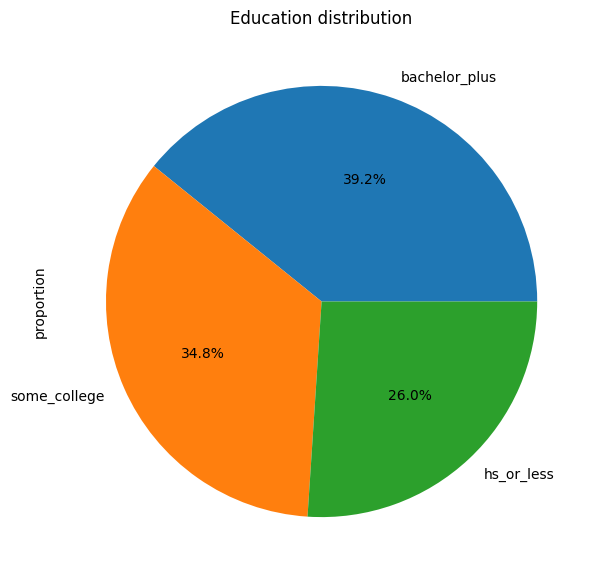

In [78]:
education_distribution.plot(kind = 'pie', autopct = '%1.1f%%', figsize  = (7,7), title = 'Education distribution')


<Axes: title={'center': 'Job distribution'}, ylabel='proportion'>

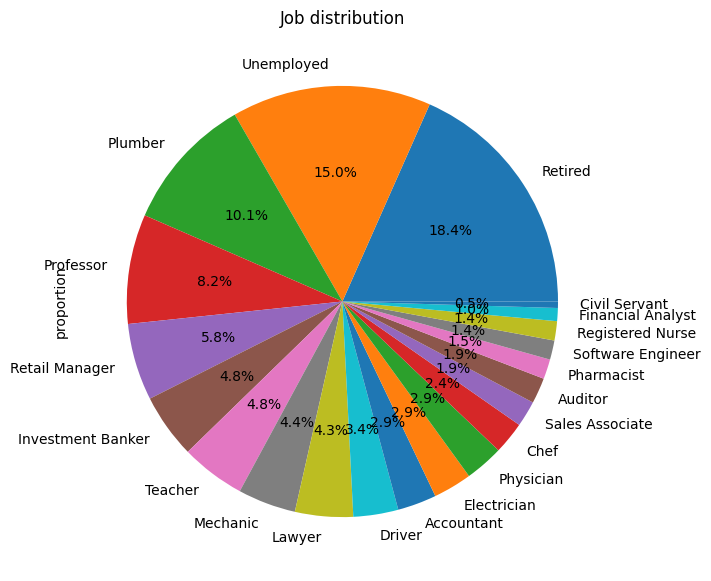

In [79]:
job_distribution.plot(kind = 'pie', autopct = '%1.1f%%', figsize  = (7,7), title = 'Job distribution')

In [ ]:
import seaborn as sns


### Attribute Correlation & Heatmap Analysis

The following code performs normalization and correlation analysis across major numeric, derived, and encoded attributes in the dataset.

1. **Derived Attributes**: Calculates customer `age`, transaction `trans_hour`, and customer-to-merchant `distance_km`.
2. **Categorical Encoding**: Maps ordinal and binary attributes (`gender`, `income_band`, `education`, `marital_status`, `merchant_size`) to numeric codes.
3. **Robust Normalization**: Calculates **Spearman Rank Correlation** to normalize pairwise relationships into `[-1.0, 1.0]`, resilient to non-linearities and extreme transaction/fraud outliers.


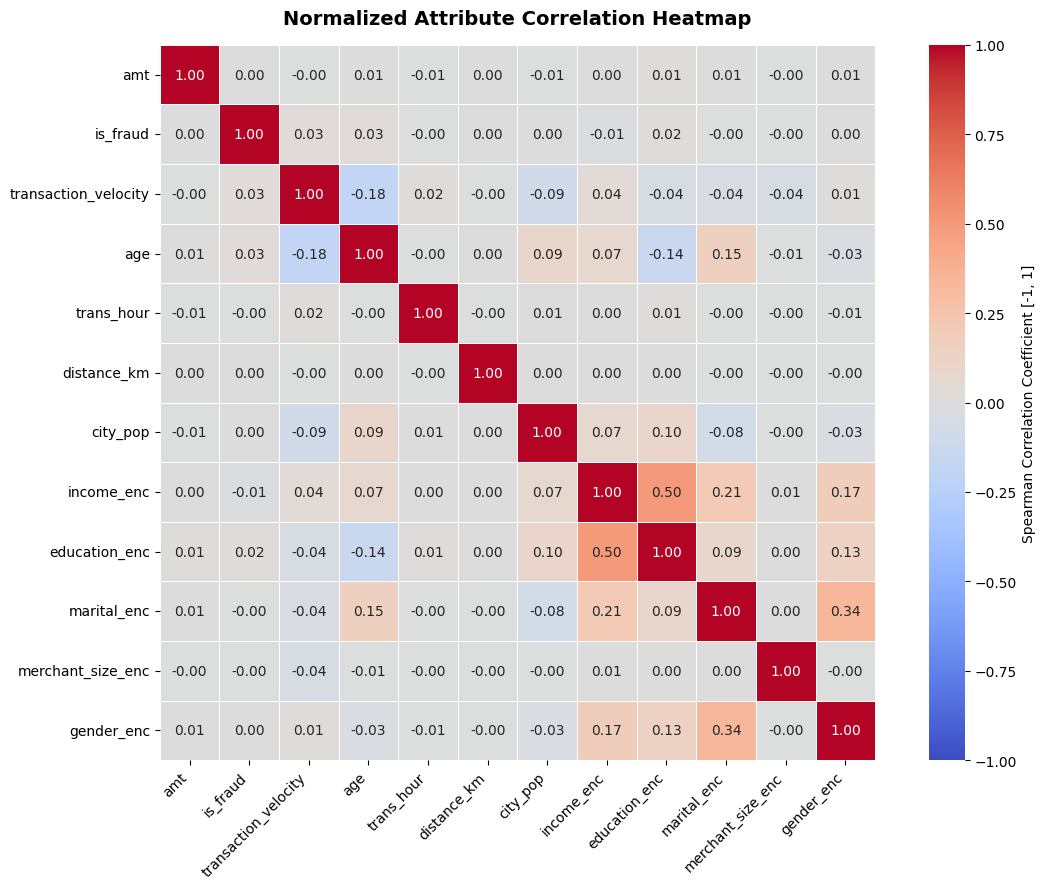

In [82]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Feature Engineering & Derived Attributes
df_attr = df.copy()
df_attr["age"] = (pd.to_datetime(df_attr["trans_date"]) - pd.to_datetime(df_attr["dob"])).dt.days // 365
df_attr["trans_hour"] = pd.to_datetime(df_attr["trans_time"], format="%H:%M:%S").dt.hour
df_attr["distance_km"] = np.sqrt(
    (df_attr["lat"] - df_attr["merch_lat"])**2 + 
    (df_attr["long"] - df_attr["merch_long"])**2
) * 111  # Approximate distance in km

# 2. Categorical Encoding (Matching Dataset Categories)
gender_map = {"M": 0, "F": 1}
income_map = {"<50k": 0, "50-100k": 1, "100k+": 2}
edu_map = {"hs_or_less": 0, "some_college": 1, "bachelor_plus": 2}
marital_map = {"never_married": 0, "formerly_married": 1, "married": 2}
size_map = {"small": 0, "medium": 1, "large": 2}

df_attr["gender_enc"] = df_attr["gender"].map(gender_map)
df_attr["income_enc"] = df_attr["income_band"].map(income_map)
df_attr["education_enc"] = df_attr["education"].map(edu_map)
df_attr["marital_enc"] = df_attr["marital_status"].map(marital_map)
df_attr["merchant_size_enc"] = df_attr["merchant_size"].map(size_map)

# Selected Numerical & Encoded Features
features = [
    "amt", "is_fraud", "transaction_velocity", "age", "trans_hour", 
    "distance_km", "city_pop", "income_enc", "education_enc", 
    "marital_enc", "merchant_size_enc", "gender_enc"
]

corr_subset = df_attr[features].dropna()

# 3. Compute Spearman Rank Correlation (Normalized [-1, 1])
corr_matrix = corr_subset.corr(method="spearman")

# 4. Plot Normalized Attribute Heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Spearman Correlation Coefficient [-1, 1]"}
)

plt.title("Normalized Attribute Correlation Heatmap", fontsize=14, fontweight="bold", pad=15)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()


In [83]:
categories_marital = new['marital_status'].unique()
print(categories_marital)

['married' 'never_married' 'formerly_married']
